In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

TRAIN_PATH = "/kaggle/input/competitions/T2-IF3170-2026-2027/train.csv"
TEST_PATH = "/kaggle/input/competitions/T2-IF3170-2026-2027/test.csv"

train_raw = pd.read_csv(TRAIN_PATH, dtype={"id": str})
test_raw = pd.read_csv(TEST_PATH, dtype={"id": str})

print("Train shape:", train_raw.shape)
print("Test shape :", test_raw.shape)
train_raw.head()

Train shape: (27373, 19)
Test shape : (6844, 18)


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


In [16]:
print("\nTRAIN INFO")
train_raw.info()
print("TEST INFO")
test_raw.info()

num_cols = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "arrival_year", "arrival_month", "arrival_day",
    "prior_cancellations", "prior_completed_bookings",
    "nightly_rate_idr", "special_requests"
]
cat_cols = ["meal_package", "room_category", "booking_channel"]
bin_cols = ["needs_parking", "is_returning_guest"]
target_col = "is_canceled"


TRAIN INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  object 
 13  is_returning_guest        27373 non-null  int64  

In [17]:
def missing_report(df, name):
    miss = df.isna().sum()
    pct = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({"missing_count": miss, "missing_pct": pct})
    report = report[report["missing_count"] > 0].sort_values("missing_pct", ascending=False)
    print(f"--- Missing values: {name} ---")
    print(report if not report.empty else "Tidak ada missing value.")
    return report

miss_train = missing_report(train_raw, "train")
miss_test = missing_report(test_raw, "test")

print("\nJumlah baris duplikat (train):", train_raw.duplicated().sum())
print("Jumlah baris duplikat (test) :", test_raw.duplicated().sum())

print("id duplikat (train):", train_raw["id"].duplicated().sum())
print("id duplikat (test) :", test_raw["id"].duplicated().sum())

--- Missing values: train ---
                     missing_count  missing_pct
num_children                  3035        11.09
special_requests              2500         9.13
nightly_rate_idr              2038         7.45
meal_package                  1760         6.43
days_before_arrival           1123         4.10
needs_parking                 1082         3.95
room_category                 1002         3.66
num_adults                     809         2.96
--- Missing values: test ---
                     missing_count  missing_pct
num_children                   747        10.91
special_requests               593         8.66
nightly_rate_idr               540         7.89
meal_package                   442         6.46
days_before_arrival            290         4.24
needs_parking                  247         3.61
room_category                  242         3.54
num_adults                     180         2.63

Jumlah baris duplikat (train): 0
Jumlah baris duplikat (test) : 0
id duplika

is_canceled
0    18404
1     8969
Name: count, dtype: int64
is_canceled
0    67.2
1    32.8
Name: proportion, dtype: float64


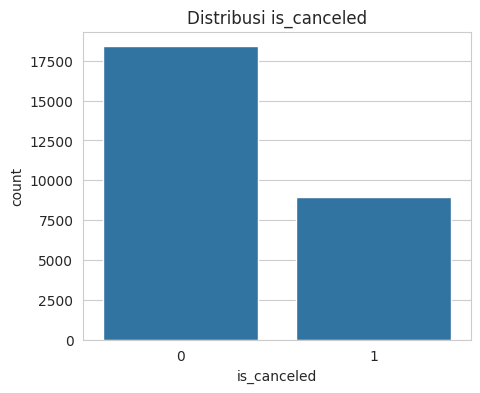

In [18]:
print(train_raw[target_col].value_counts())
# hitung persentasenya setiap kelas target
print(train_raw[target_col].value_counts(normalize=True).round(3) * 100)

plt.figure(figsize=(5,4))
sns.countplot(data=train_raw, x=target_col)
plt.title("Distribusi is_canceled")
plt.show()

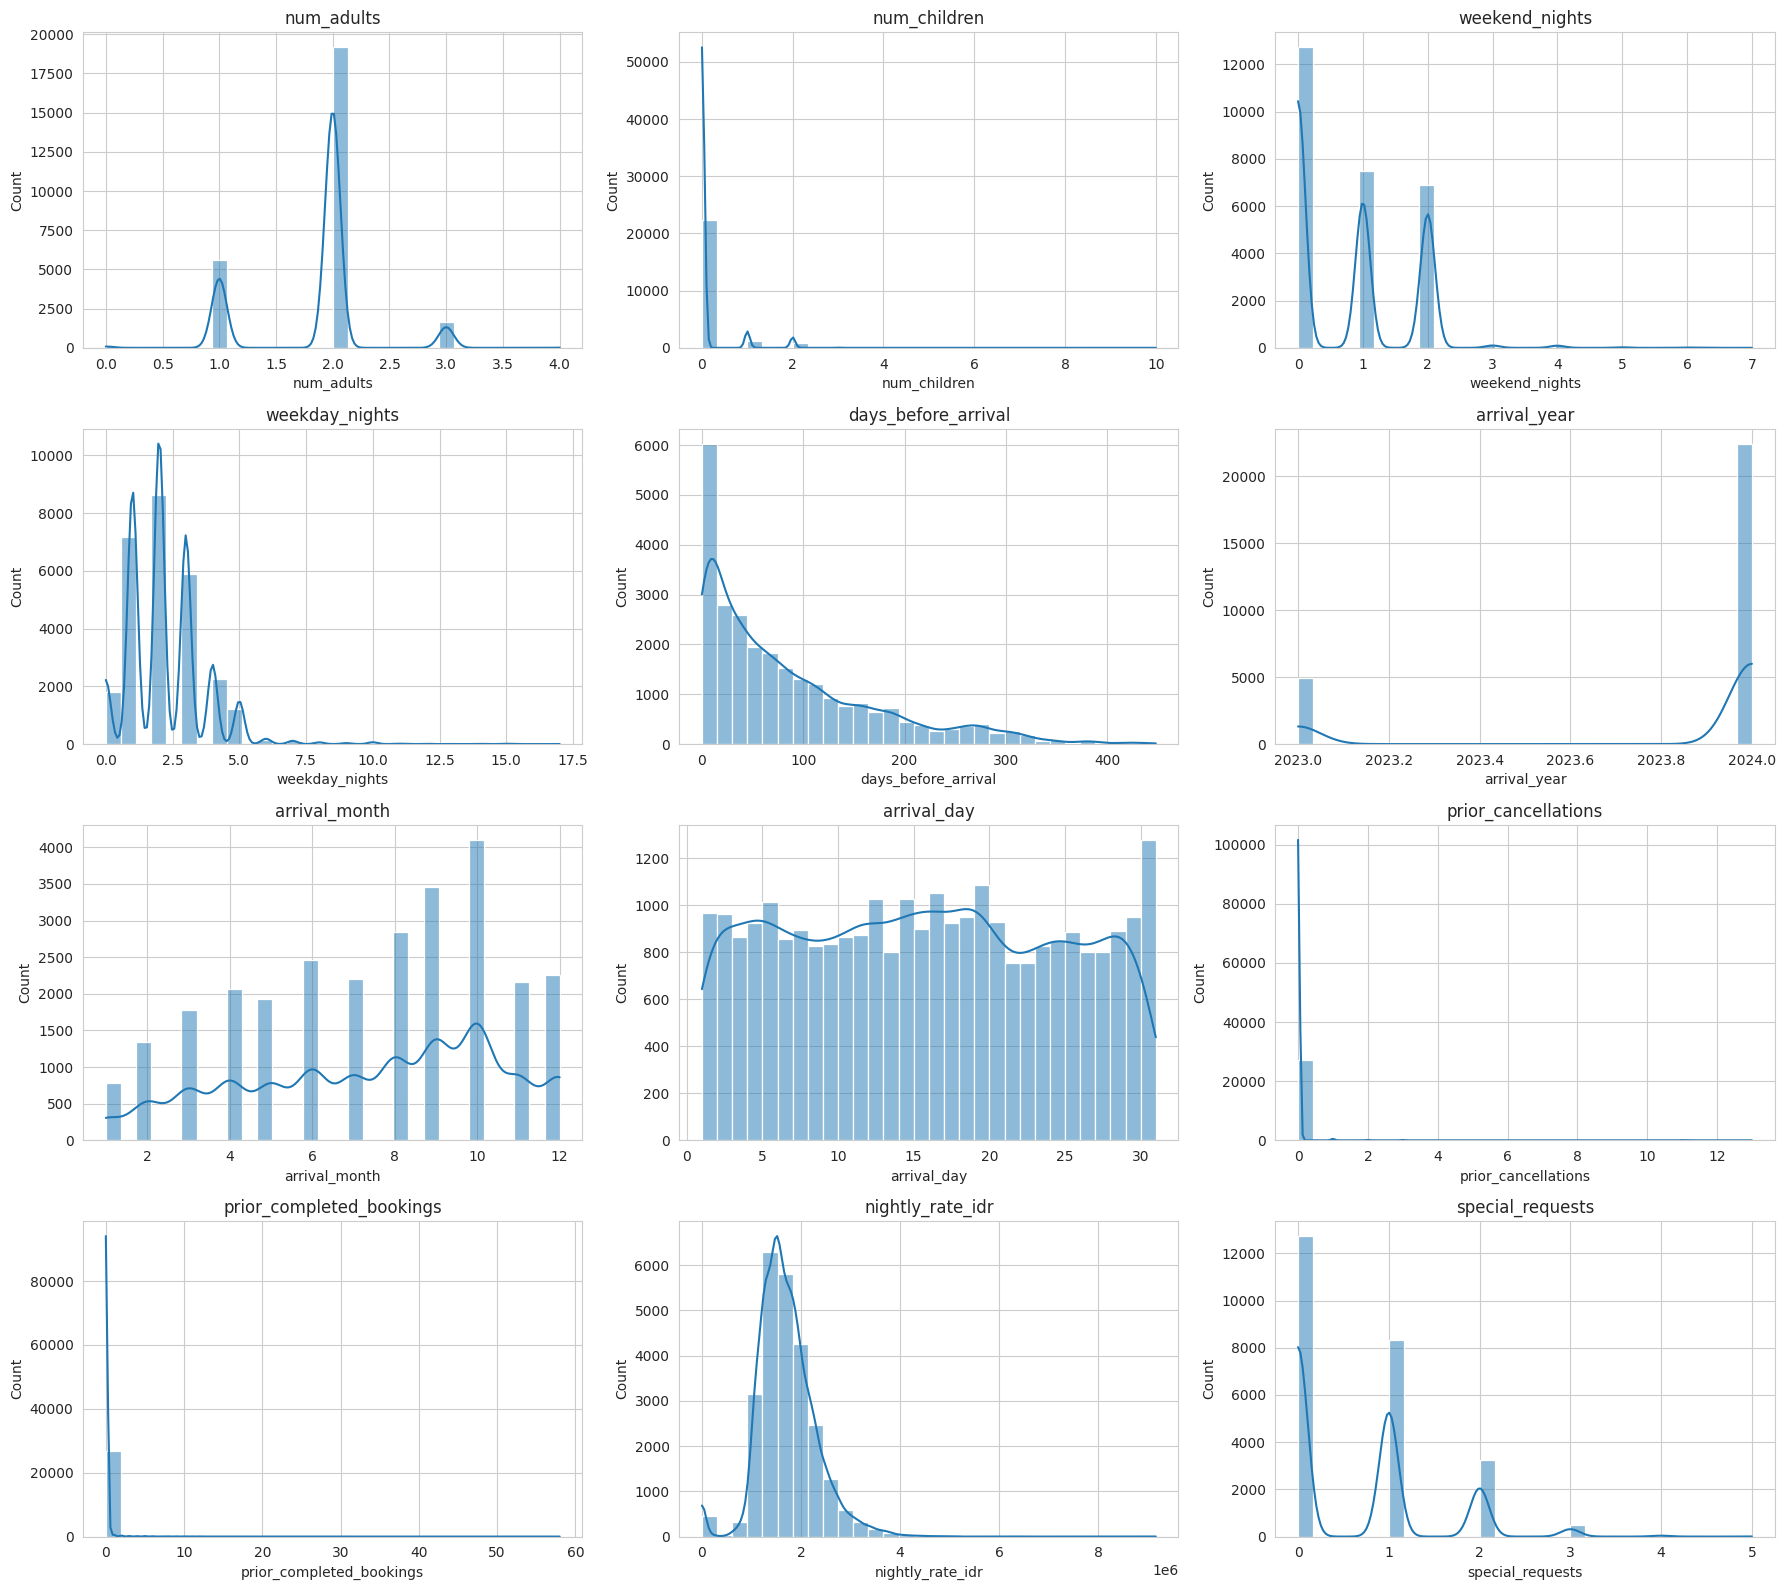

In [19]:

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(train_raw[col].dropna(), bins=30, ax=axes[i], kde=True)
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

Booking dengan nightly_rate_idr = 0: 413 (1.51%)
booking_channel   Airline  Complimentary  Corporate  Offline Agent  \
nightly_rate_idr                                                     
False                  88             34       1513           7960   
True                    0            267          0              0   

booking_channel   Online Travel Agent  
nightly_rate_idr                       
False                           17365  
True                              146  


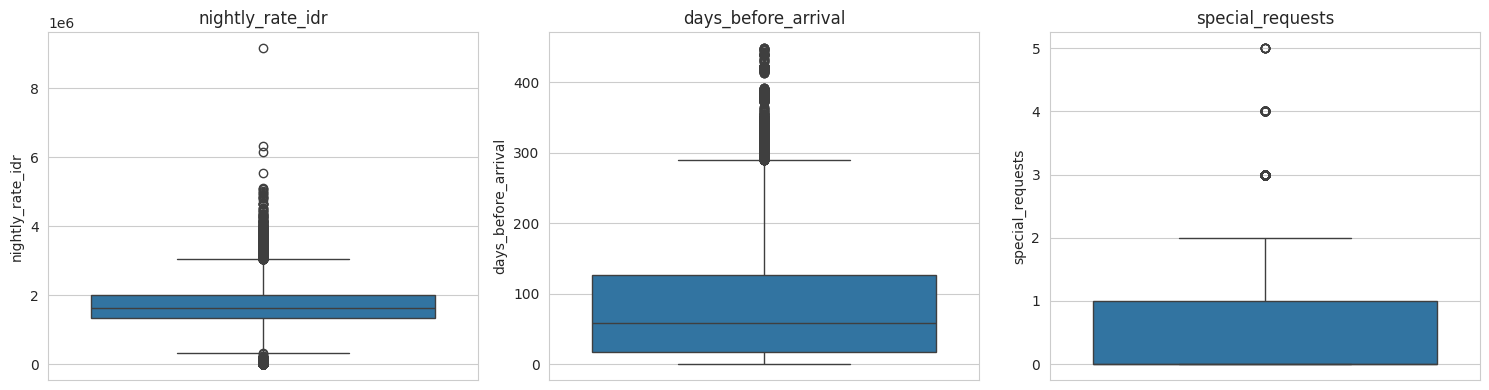

num_adults: 7400 potential outliers (IQR rule)
num_children: 2020 potential outliers (IQR rule)
weekend_nights: 16 potential outliers (IQR rule)
weekday_nights: 258 potential outliers (IQR rule)
days_before_arrival: 916 potential outliers (IQR rule)
arrival_year: 4924 potential outliers (IQR rule)
arrival_month: 0 potential outliers (IQR rule)
arrival_day: 0 potential outliers (IQR rule)
prior_cancellations: 241 potential outliers (IQR rule)
prior_completed_bookings: 600 potential outliers (IQR rule)
nightly_rate_idr: 1144 potential outliers (IQR rule)
special_requests: 563 potential outliers (IQR rule)


In [20]:
# nightly_rate_idr = 0 biasanya complimentary stay
zero_rate = (train_raw["nightly_rate_idr"] == 0).sum()
print(f"Booking dengan nightly_rate_idr = 0: {zero_rate} "
      f"({zero_rate/len(train_raw)*100:.2f}%)")

#  ngecek booking_channel == 'Complimentary' konsisten dengan rate 0?
print(pd.crosstab(train_raw["nightly_rate_idr"] == 0, train_raw["booking_channel"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=train_raw["nightly_rate_idr"], ax=axes[0]).set_title("nightly_rate_idr")
sns.boxplot(y=train_raw["days_before_arrival"], ax=axes[1]).set_title("days_before_arrival")
sns.boxplot(y=train_raw["special_requests"], ax=axes[2]).set_title("special_requests")
plt.tight_layout()
plt.show()

# IQR-based outlier count 
def iqr_outlier_count(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((s < lo) | (s > hi)).sum()

for col in num_cols:
    print(f"{col}: {iqr_outlier_count(train_raw[col].dropna())} potential outliers (IQR rule)")

--- meal_package ---
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
NaN            1760
Full Board        4
Name: count, dtype: int64

--- room_category ---
room_category
Type B    20447
Type G     4396
NaN        1002
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64

--- booking_channel ---
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64

--- needs_parking ---
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64

--- is_returning_guest ---
is_returning_guest
0    26684
1      689
Name: count, dtype: int64



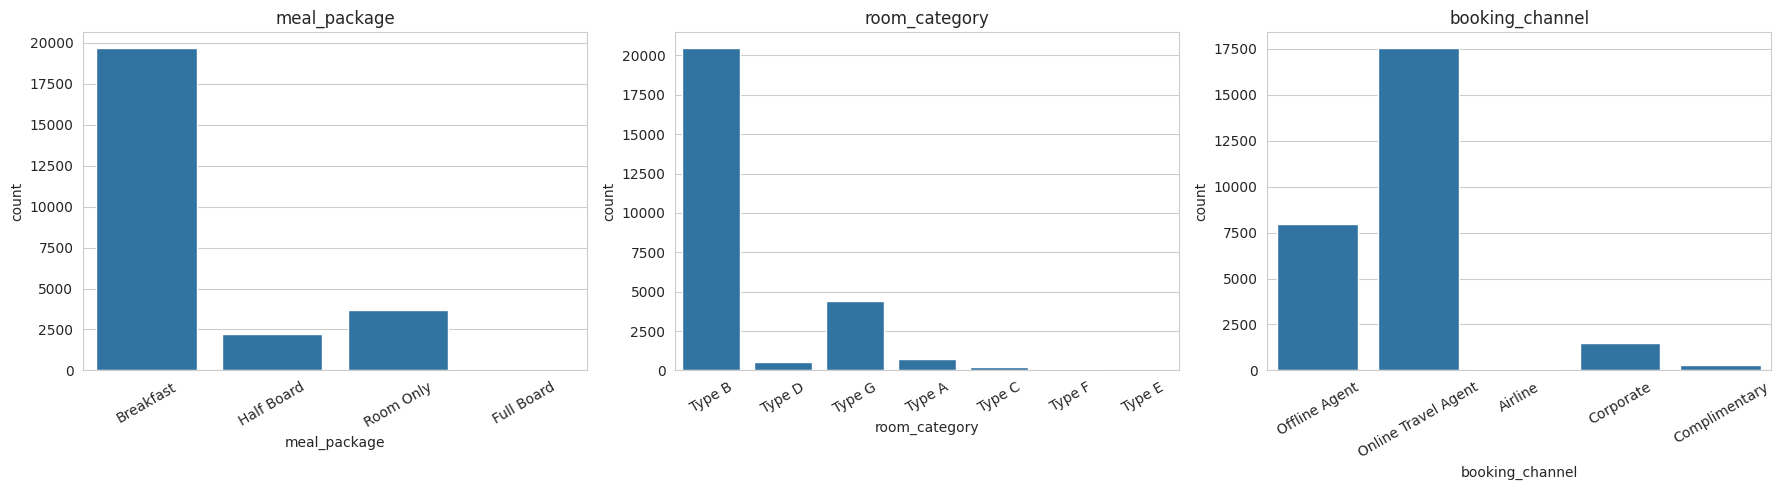

In [21]:
for col in cat_cols + bin_cols:
    print(f"--- {col} ---")
    print(train_raw[col].value_counts(dropna=False))
    print()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(cat_cols):
    sns.countplot(data=train_raw, x=col, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

Korelasi fitur numerik dengan is_canceled:
 days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
special_requests           -0.257996
Name: is_canceled, dtype: float64


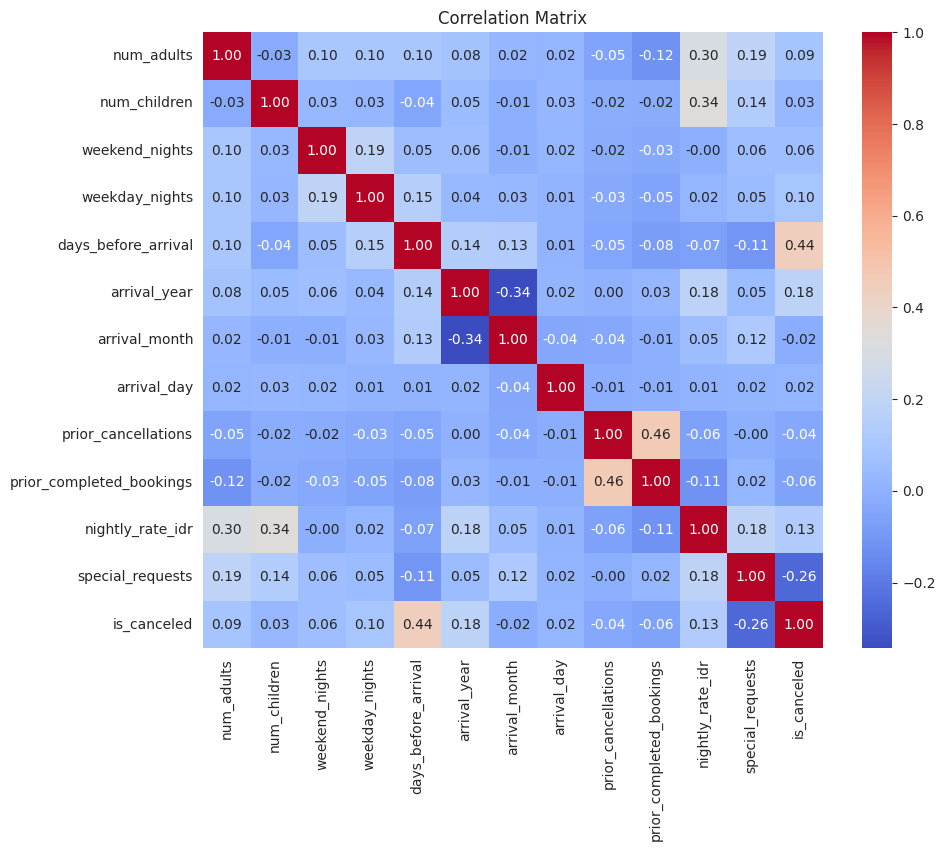


Cancellation rate per meal_package:
 meal_package
Half Board    0.459
Room Only     0.338
Breakfast     0.311
Full Board    0.250
Name: is_canceled, dtype: float64

Cancellation rate per room_category:
 room_category
Type A    0.426
Type G    0.342
Type D    0.329
Type B    0.321
Type E    0.286
Type C    0.249
Type F    0.244
Name: is_canceled, dtype: float64

Cancellation rate per booking_channel:
 booking_channel
Online Travel Agent    0.364
Airline                0.307
Offline Agent          0.302
Corporate              0.115
Complimentary          0.000
Name: is_canceled, dtype: float64


In [22]:
# numerik vs target
corr_with_target = train_raw[num_cols + [target_col]].corr()[target_col].drop(target_col)
print("Korelasi fitur numerik dengan is_canceled:\n", corr_with_target.sort_values(ascending=False))

plt.figure(figsize=(10,8))
sns.heatmap(train_raw[num_cols + [target_col]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# kategorikal vs target 
for col in cat_cols:
    rate = train_raw.groupby(col)[target_col].mean().sort_values(ascending=False)
    print(f"\nCancellation rate per {col}:\n", rate.round(3))

In [23]:
# booking dengan total nights = 0 (weekend+weekday nights)
zero_nights = train_raw[(train_raw["weekend_nights"] == 0) & (train_raw["weekday_nights"] == 0)]
print("Booking dengan total menginap 0 malam:", len(zero_nights))

# booking dengan 0 tamu (adults + children)
zero_guests = train_raw[(train_raw["num_adults"] == 0) & (train_raw["num_children"] == 0)]
print("Booking dengan 0 tamu:", len(zero_guests))

# arrival_day valid terhadap arrival_month (misal 31 di bulan Februari)
import calendar
def invalid_date_mask(df):
    def check(row):
        try:
            max_day = calendar.monthrange(int(row["arrival_year"]), int(row["arrival_month"]))[1]
            return row["arrival_day"] > max_day
        except Exception:
            return False
    return df.apply(check, axis=1)

invalid_dates = train_raw[invalid_date_mask(train_raw)]
print("Baris dengan arrival_day tidak valid:", len(invalid_dates))

Booking dengan total menginap 0 malam: 64
Booking dengan 0 tamu: 0
Baris dengan arrival_day tidak valid: 0


In [24]:
def clean_data(df, is_train=True, imputers=None):
    
    df = df.copy()
    fitted_imputers = {} if imputers is None else imputers

    # 1. hapus data yang duplikat
    if is_train:
        before = len(df)
        df = df.drop_duplicates()
        print(f"[train] Dihapus {before - len(df)} baris duplikat")

    # 2. imputasi numerik -> median (robust terhadap outlier)
    for col in num_cols:
        if col not in df.columns:
            continue
        if imputers is None:
            fitted_imputers[col] = df[col].median()
        df[col] = df[col].fillna(fitted_imputers[col])

    # 3. imputasi kategorikal -> modus
    for col in cat_cols:
        if col not in df.columns:
            continue
        if imputers is None:
            fitted_imputers[col] = df[col].mode()[0]
        df[col] = df[col].fillna(fitted_imputers[col])

    # 3b. imputasi binary -> modus 
    for col in bin_cols:
        if col not in df.columns:
            continue
        if imputers is None:
            fitted_imputers[col] = df[col].mode()[0]
        df[col] = df[col].fillna(fitted_imputers[col])

    
    int_like = ["num_adults", "num_children", "weekend_nights", "weekday_nights",
                "needs_parking", "arrival_year", "arrival_month", "arrival_day",
                "is_returning_guest", "prior_cancellations", "prior_completed_bookings",
                "nightly_rate_idr", "special_requests"]

    # memastikan tidak ada NaN tersisa sebelum cast ke int
    remaining_na = df[int_like].isna().sum()
    if remaining_na.sum() > 0:
        print("Masih ada NaN di kolom berikut, akan diisi dengan median sebagai fallback:")
        print(remaining_na[remaining_na > 0])
        for col in int_like:
            if df[col].isna().sum() > 0:
                fallback = fitted_imputers.get(col, df[col].median())
                df[col] = df[col].fillna(fallback)

    for col in int_like:
        if col in df.columns:
            df[col] = df[col].round().astype(int)

    # 4. buang baris invalid yang jelas corrupt 
    if is_train:
        invalid_mask = (df["weekend_nights"] == 0) & (df["weekday_nights"] == 0)
        # df = df[~invalid_mask]  

    return (df, fitted_imputers) if imputers is None else df


# --- jalankan terpisah untuk train dan test ---
train_clean, imputers = clean_data(train_raw, is_train=True, imputers=None)
test_clean = clean_data(test_raw, is_train=False, imputers=imputers)

print("\nSisa missing value train:", train_clean.isna().sum().sum())
print("Sisa missing value test :", test_clean.isna().sum().sum())

train_clean.to_csv("/kaggle/working/train_clean.csv", index=False)
test_clean.to_csv("/kaggle/working/test_clean.csv", index=False)

print("\nSaved: /kaggle/working/train_clean.csv")
print("Saved: /kaggle/working/test_clean.csv")

[train] Dihapus 0 baris duplikat

Sisa missing value train: 0
Sisa missing value test : 0

Saved: /kaggle/working/train_clean.csv
Saved: /kaggle/working/test_clean.csv
